<a href="https://colab.research.google.com/github/f2023376383-ops/big-data-project2/blob/main/Big_Data_Analytics_Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Big Data Analytics — Project 2
## Digital Advertising Budget Optimizer
**Business question:** A Pakistani clothing brand spends money on Facebook, Instagram, Google, TikTok and YouTube. Management asks: **where should we spend the next Rs. 1 million?**

> **Important note about the data:** This project uses **simulated (synthetic) paid-campaign data**. It is *not* real data from any brand. The platform numbers (CTR, CPC, conversion rate, order value) are illustrative assumptions I chose to make a realistic workflow. The findings show the *method*, not real market facts about Pakistan.

**This notebook follows the same workflow as Project 1:**
1. Generate and describe the data (data dictionary)
2. Quality checks
3. Marketing metrics (CTR, CPC, CPA, conversion rate, ROAS)
4. EDA with charts
5. Scaling experiment: Pandas vs MapReduce vs Spark (10K to 10M rows)
6. Marketing Budget Recommendation Engine
7. Limitations and conclusion

## Step 0 — Setup

In [1]:
import importlib.util, subprocess, sys, os, time, csv, itertools
from collections import defaultdict

# PySpark is installed automatically if it is missing (Colab has Java already).
if importlib.util.find_spec("pyspark") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)
DATA_DIR = "bd_data"
os.makedirs(DATA_DIR, exist_ok=True)
print("Setup done.")

Setup done.


## Step 1 — Create the simulated advertising data

**One row = one ad record** (one campaign, on one platform, on one day, for one audience segment).

### Data dictionary
| Column | Type | Meaning |
|---|---|---|
| date | Date | Day of the ad record (year 2025) |
| campaign | Category | Winter Collection, Eid Collection, Summer Lawn Sale, Brand Awareness, 11.11 Sale, 12.12 Sale |
| platform | Category | Facebook, Instagram, Google, TikTok, YouTube |
| impressions | Number | How many times the ad was shown |
| clicks | Number | How many times people clicked |
| spend | Number | Money spent (Rs.) |
| conversions | Number | Number of purchases |
| revenue | Number | Sales value (Rs.) |
| age_group | Category | 18-24, 25-34, 35-44, 45+ |
| gender | Category | Female / Male |
| city | Category | Lahore, Karachi, Islamabad, Rawalpindi, Faisalabad, Multan, Peshawar |
| device | Category | Mobile / Desktop / Tablet |

### How the simulation works (so it is honest and explainable)
- Each platform has its own average CTR, CPC, conversion rate and order value (table below). These are **my assumptions**.
- Random noise is added to every record so no two rows are the same.
- Campaigns follow the calendar (Eid in Mar-Apr, 11.11 in early Nov, 12.12 in early Dec).
- Clicks cannot be more than impressions, and conversions cannot be more than clicks.

In [2]:
# Illustrative assumptions per platform (NOT real market data)
PLATFORMS = {
    #            avg impressions, CTR,   CPC (Rs), conv. rate, avg order value (Rs), share of rows
    "Facebook":  dict(impr=8000,  ctr=0.011, cpc=18, cvr=0.022, aov=4200, share=0.25),
    "Instagram": dict(impr=7000,  ctr=0.014, cpc=22, cvr=0.028, aov=4800, share=0.25),
    "Google":    dict(impr=4000,  ctr=0.032, cpc=35, cvr=0.040, aov=5200, share=0.20),
    "TikTok":    dict(impr=12000, ctr=0.009, cpc=12, cvr=0.014, aov=3800, share=0.18),
    "YouTube":   dict(impr=9000,  ctr=0.006, cpc=15, cvr=0.010, aov=4500, share=0.12),
}
CAMPAIGN_EFFECT = {  # (impressions multiplier, conversion-rate multiplier)
    "Winter Collection": (1.0, 1.00), "Eid Collection": (1.1, 1.25),
    "Summer Lawn Sale": (1.0, 1.00),  "Brand Awareness": (1.5, 0.60),
    "11.11 Sale": (1.2, 1.30),        "12.12 Sale": (1.2, 1.25),
}
DEVICES = {"Mobile": (0.72, 0.95), "Desktop": (0.22, 1.20), "Tablet": (0.06, 1.00)}   # (probability, cvr multiplier)
AGES    = {"18-24": (0.30, 0.90), "25-34": (0.38, 1.10), "35-44": (0.20, 1.05), "45+": (0.12, 0.95)}
CITIES  = {"Lahore": .24, "Karachi": .28, "Islamabad": .12, "Rawalpindi": .08, "Faisalabad": .10, "Multan": .09, "Peshawar": .09}
COLUMNS = ["date","campaign","platform","impressions","clicks","spend","conversions","revenue",
           "age_group","gender","city","device"]

def generate_ads(n, seed=42):
    """Create n simulated ad records (vectorised, so 10 million rows is possible)."""
    rng = np.random.default_rng(seed)
    plat_names = np.array(list(PLATFORMS))
    p_idx = rng.choice(len(plat_names), size=n, p=[PLATFORMS[p]["share"] for p in plat_names])
    par = lambda key: np.array([PLATFORMS[p][key] for p in plat_names], dtype=float)[p_idx]

    # --- dates and campaigns (calendar based) ---
    day  = rng.integers(0, 365, size=n)
    date = np.datetime64("2025-01-01") + day.astype("timedelta64[D]")
    month = date.astype("datetime64[M]").astype(int) % 12 + 1
    dom   = (date - date.astype("datetime64[M]")).astype(int) + 1
    camp_names = np.array(list(CAMPAIGN_EFFECT))
    camp = np.select(
        [month <= 2, month <= 4, month <= 8, month <= 10, (month == 11) & (dom <= 15), month == 11, (month == 12) & (dom <= 15)],
        ["Winter Collection", "Eid Collection", "Summer Lawn Sale", "Brand Awareness", "11.11 Sale", "Winter Collection", "12.12 Sale"],
        default="Winter Collection")
    c_idx = np.searchsorted(np.sort(camp_names), camp)           # integer code for each campaign
    sorted_names = np.sort(camp_names)
    impr_mult = np.array([CAMPAIGN_EFFECT[c][0] for c in sorted_names])[c_idx]
    cvr_mult  = np.array([CAMPAIGN_EFFECT[c][1] for c in sorted_names])[c_idx]

    # --- audience ---
    dev_names, age_names, city_names = list(DEVICES), list(AGES), list(CITIES)
    d_idx = rng.choice(len(dev_names),  size=n, p=[DEVICES[d][0] for d in dev_names])
    a_idx = rng.choice(len(age_names),  size=n, p=[AGES[a][0] for a in age_names])
    y_idx = rng.choice(len(city_names), size=n, p=list(CITIES.values()))
    g_idx = rng.choice(2, size=n, p=[0.62, 0.38])
    cvr_mult = cvr_mult * np.array([DEVICES[d][1] for d in dev_names])[d_idx] * np.array([AGES[a][1] for a in age_names])[a_idx]

    # --- funnel: impressions -> clicks -> conversions -> revenue ---
    noise = lambda s: rng.lognormal(-s * s / 2, s, size=n)          # noise with average 1
    impressions = np.maximum((par("impr") * impr_mult * noise(0.6)).astype(np.int64), 50)
    ctr    = np.clip(par("ctr") * noise(0.20), 0.0005, 0.30)
    clicks = rng.binomial(impressions, ctr)
    spend  = np.round(clicks * par("cpc") * noise(0.20), 2)
    cvr    = np.clip(par("cvr") * cvr_mult * noise(0.20), 0.0, 0.60)
    conversions = rng.binomial(clicks, cvr)
    revenue = np.round(conversions * par("aov") * noise(0.25), 2)

    return pd.DataFrame({
        "date": date.astype("datetime64[ns]"),
        "campaign": pd.Categorical(camp),
        "platform": pd.Categorical.from_codes(p_idx, plat_names),
        "impressions": impressions, "clicks": clicks, "spend": spend,
        "conversions": conversions, "revenue": revenue,
        "age_group": pd.Categorical.from_codes(a_idx, age_names),
        "gender": pd.Categorical.from_codes(g_idx, ["Female", "Male"]),
        "city": pd.Categorical.from_codes(y_idx, city_names),
        "device": pd.Categorical.from_codes(d_idx, dev_names),
    })[COLUMNS]

df = generate_ads(10_000, seed=42)
df.to_csv(f"{DATA_DIR}/ads_backup_original.csv", index=False)   # backup copy of the original data
display(df.head())
print("Rows, columns:", df.shape)

,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age_group,gender,city,device
0,2025-01-13,Winter Collection,TikTok,16142,201,"1,816.940",0,0.000,45+,Male,Lahore,Mobile
1,2025-09-21,Brand Awareness,Instagram,9600,105,"2,558.720",0,0.000,45+,Male,Lahore,Mobile
2,2025-03-20,Eid Collection,TikTok,24125,198,"2,321.660",4,"15,640.880",35-44,Female,Karachi,Mobile
3,2025-09-17,Brand Awareness,Google,3691,120,"3,687.630",4,"29,109.920",25-34,Female,Faisalabad,Desktop
4,2025-07-26,Summer Lawn Sale,Facebook,6601,78,887.110,5,"22,540.790",25-34,Female,Karachi,Mobile


Rows, columns: (10000, 12)


## Step 2 — Data quality checks
Same habit as Project 1: look before you calculate. Note that a platform with **zero clicks** has an undefined CPC. That is "not defined", not "zero", so I keep it as missing (NaN) and do not fill it with 0.

In [3]:
print("Rows, columns:", df.shape)
display(df.dtypes.to_frame("dtype").T)
print("\nMissing values per column:"); display(df.isna().sum().to_frame("missing").T)
print("Duplicate rows:", df.duplicated().sum())

print("\nLogic checks (all should be 0):")
print("  clicks > impressions   :", (df["clicks"] > df["impressions"]).sum())
print("  conversions > clicks   :", (df["conversions"] > df["clicks"]).sum())
print("  negative spend/revenue :", ((df["spend"] < 0) | (df["revenue"] < 0)).sum())
print("  rows with zero clicks  :", (df["clicks"] == 0).sum(), "(CPC is undefined for these rows)")

display(df.describe(include="all").T)

Rows, columns: (10000, 12)


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age_group,gender,city,device
dtype,datetime64[ns],category,category,int64,int64,float64,int64,float64,category,category,category,category



Missing values per column:


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age_group,gender,city,device
missing,0,0,0,0,0,0,0,0,0,0,0,0


Duplicate rows: 0

Logic checks (all should be 0):
  clicks > impressions   : 0
  conversions > clicks   : 0
  negative spend/revenue : 0
  rows with zero clicks  : 0 (CPC is undefined for these rows)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,10000,NaN,NaN,NaN,2025-07-03 05:53:13.920000,2025-01-01 00:00:00,2025-04-02 00:00:00,2025-07-04 00:00:00,2025-10-03 00:00:00,2025-12-31 00:00:00,NaN
campaign,10000,6,Summer Lawn Sale,3358,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,10000,5,Facebook,2545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
impressions,"10,000.000",NaN,NaN,NaN,"8,643.043",459.000,"4,183.750","6,749.500","10,858.000","86,346.000","6,961.972"
clicks,"10,000.000",NaN,NaN,NaN,110.099,5.000,54.000,86.000,138.000,"1,037.000",87.434
spend,"10,000.000",NaN,NaN,NaN,"2,451.010",70.010,907.355,"1,613.025","3,005.900","32,676.560","2,627.294"
conversions,"10,000.000",NaN,NaN,NaN,2.851,0.000,1.000,2.000,4.000,37.000,3.505
revenue,"10,000.000",NaN,NaN,NaN,"13,532.731",0.000,"3,022.030","7,685.060","17,472.455","241,218.210","18,921.255"
age_group,10000,4,25-34,3779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,10000,2,Female,6226,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 3 — Marketing metrics
| Metric | Formula | Meaning |
|---|---|---|
| CTR | clicks / impressions | How many people who saw the ad clicked it |
| CPC | spend / clicks | Cost of one click |
| CPA | spend / conversions | Cost of one purchase |
| Conversion rate (CVR) | conversions / clicks | How many clickers bought |
| ROAS | revenue / spend | Rs. earned for each Rs. 1 spent |

**Common mistake to avoid:** when comparing platforms, calculate the metric from the **totals** (total revenue ÷ total spend). Do *not* average the row-level ROAS values, because a tiny ad record would count as much as a huge one.

In [4]:
SUM_COLS = ["impressions", "clicks", "spend", "conversions", "revenue"]

def safe_div(a, b):
    """Division that returns NaN (not an error, not 0) when the denominator is 0."""
    return a / b.where(b != 0)

def summarize(data, by):
    """Group the data and calculate every metric from the group TOTALS."""
    g = data.groupby(by, observed=True)[SUM_COLS].sum()
    g["records"] = data.groupby(by, observed=True).size()
    g["CTR"]  = safe_div(g["clicks"], g["impressions"])
    g["CPC"]  = safe_div(g["spend"], g["clicks"])
    g["CPA"]  = safe_div(g["spend"], g["conversions"])
    g["CVR"]  = safe_div(g["conversions"], g["clicks"])
    g["ROAS"] = safe_div(g["revenue"], g["spend"])
    return g

platform_summary = summarize(df, "platform").sort_values("ROAS", ascending=False)
display(platform_summary[["records", "spend", "revenue", "CTR", "CPC", "CPA", "CVR", "ROAS"]])

overall = df[SUM_COLS].sum()
print(f"\nOverall: spend Rs. {overall['spend']:,.0f} | revenue Rs. {overall['revenue']:,.0f} | ROAS {overall['revenue']/overall['spend']:.2f}")

,records,spend,revenue,CTR,CPC,CPA,CVR,ROAS
platform,,,,,,,,
Instagram,2470,"5,959,593.050","35,888,166.450",0.014,21.799,791.342,0.028,6.022
Google,2043,"10,555,759.950","62,290,501.760",0.032,35.233,887.710,0.040,5.901
Facebook,2545,"4,459,355.310","22,996,451.480",0.011,17.893,813.009,0.022,5.157
TikTok,1775,"2,528,263.930","11,053,479.540",0.009,12.037,863.773,0.014,4.372
YouTube,1167,"1,007,129.810","3,098,709.580",0.006,14.652,"1,483.255",0.010,3.077



Overall: spend Rs. 24,510,102 | revenue Rs. 135,327,309 | ROAS 5.52


## Step 4 — EDA with charts
Questions: Which platform returns the most revenue per rupee? Does a high-spend platform also earn the most? Do campaigns and devices change the result?

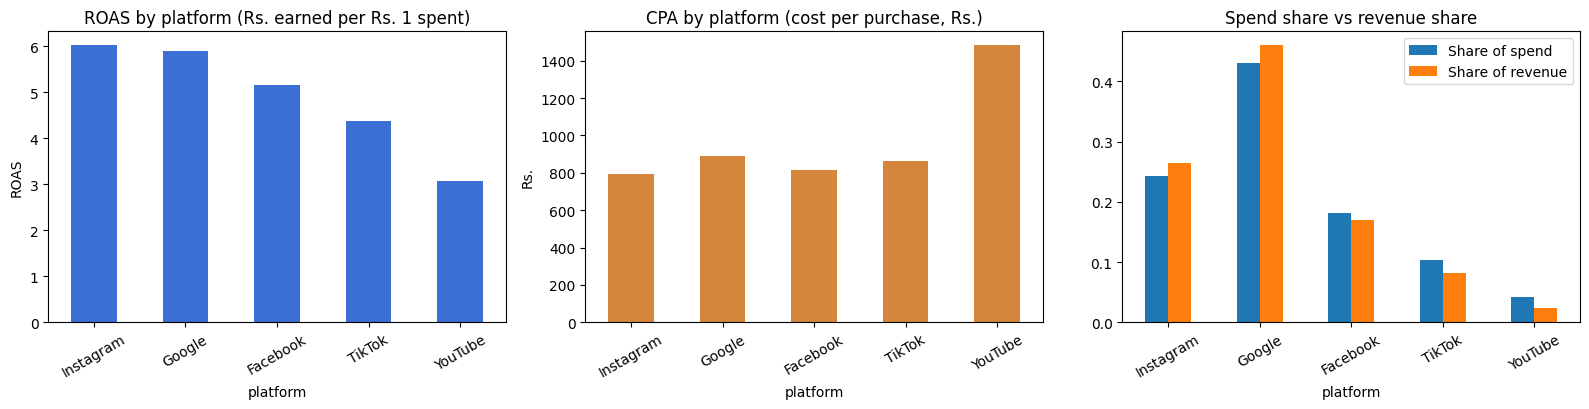

In [5]:
ps = platform_summary.copy()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ps["ROAS"].plot(kind="bar", ax=ax[0], color="#3b6fd4")
ax[0].set_title("ROAS by platform (Rs. earned per Rs. 1 spent)"); ax[0].set_ylabel("ROAS"); ax[0].tick_params(axis="x", rotation=30)

ps["CPA"].plot(kind="bar", ax=ax[1], color="#d4863b")
ax[1].set_title("CPA by platform (cost per purchase, Rs.)"); ax[1].set_ylabel("Rs."); ax[1].tick_params(axis="x", rotation=30)

share = pd.DataFrame({"Share of spend": ps["spend"] / ps["spend"].sum(), "Share of revenue": ps["revenue"] / ps["revenue"].sum()})
share.plot(kind="bar", ax=ax[2]); ax[2].set_title("Spend share vs revenue share"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

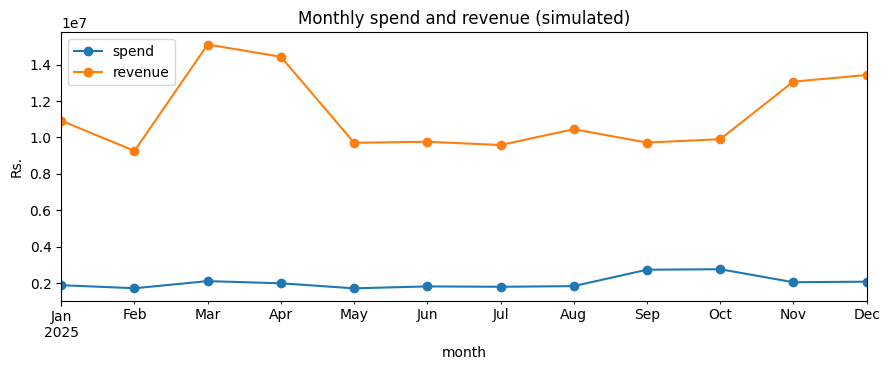

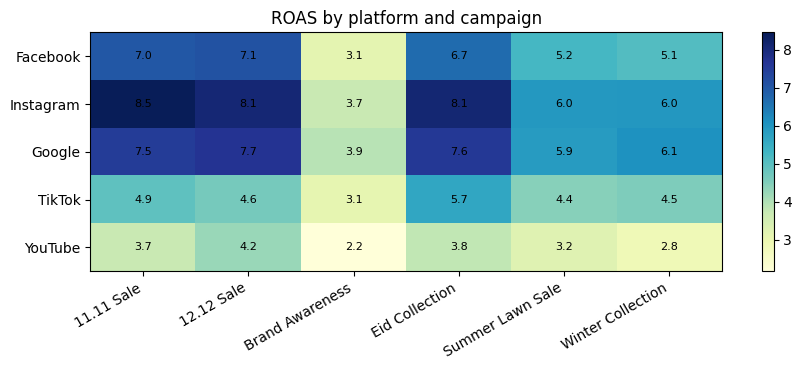

,records,spend,revenue,CVR,ROAS
device,,,,,
Desktop,2263,"5,650,519.170","37,862,664.350",0.031,6.701
Tablet,615,"1,478,714.530","7,948,308.610",0.026,5.375
Mobile,7122,"17,380,868.350","89,516,335.850",0.024,5.150


In [6]:
# Monthly trend: spend and revenue over the year
monthly = df.assign(month=df["date"].dt.to_period("M").dt.to_timestamp()).groupby("month")[["spend", "revenue"]].sum()
monthly.plot(figsize=(9, 3.8), marker="o", title="Monthly spend and revenue (simulated)")
plt.ylabel("Rs."); plt.tight_layout(); plt.show()

# ROAS by platform x campaign (heatmap)
pc = summarize(df, ["platform", "campaign"])["ROAS"].unstack()
fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(pc.values, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(pc.columns))); ax.set_xticklabels(pc.columns, rotation=30, ha="right")
ax.set_yticks(range(len(pc.index)));   ax.set_yticklabels(pc.index)
for i in range(pc.shape[0]):
    for j in range(pc.shape[1]):
        ax.text(j, i, f"{pc.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("ROAS by platform and campaign"); plt.colorbar(im); plt.tight_layout(); plt.show()

display(summarize(df, "device")[["records", "spend", "revenue", "CVR", "ROAS"]].sort_values("ROAS", ascending=False))

### Observations (write these in your own words after running)
Use this format from Project 1: **Finding → Evidence → Action → Limitation.**
- *Finding:* Which platform has the highest ROAS and which has the lowest?
- *Evidence:* Quote the numbers from the platform summary table and the first chart.
- *Action:* What should the brand test next?
- *Limitation:* This is simulated data, so it shows the method and not real market results.

## Step 5 — Scaling experiment: Pandas vs MapReduce vs Spark
**Task used for all three tools:** read the CSV file and calculate total impressions, clicks, spend, conversions and revenue **per platform** (the base of every metric above).

| Tool | How it works here |
|---|---|
| **Pandas** | Loads the whole file into memory of one computer, then `groupby`. |
| **MapReduce** | Pure-Python version of the idea: *Map* (each row becomes `platform -> numbers`), *Shuffle* (sort and group by platform), *Reduce* (add the numbers). Data is read in splits of 200,000 rows, like Hadoop input splits, with a combiner for each split. |
| **Spark** | PySpark in local mode, using all CPU cores of this machine. |

**Fair-test rules:** every tool reads the same CSV file, the data is the same, and I check that the three answers match. Spark's one-time start-up (JVM) is done before timing. The bigger files are **new simulated data of that size**, a speed and memory test and not new real-world evidence.

> Times depend on the computer. Colab has only 2 CPU cores, so do not expect Spark to be hugely faster. This is a measurement, not a guaranteed win.

In [7]:
SIZES = [10_000, 100_000, 1_000_000, 10_000_000]
MAPREDUCE_MAX_ROWS = 10_000_000     # lower this (e.g. 1_000_000) if MapReduce takes too long on your machine

for n in SIZES:
    path = f"{DATA_DIR}/ads_{n}.csv"
    if not os.path.exists(path):
        t = time.perf_counter()
        generate_ads(n, seed=42).to_csv(path, index=False)
        print(f"{n:>10,} rows written ({os.path.getsize(path)/1e6:,.1f} MB) in {time.perf_counter()-t:.1f}s")
    else:
        print(f"{n:>10,} rows already exist")

    10,000 rows written (0.9 MB) in 0.2s
   100,000 rows written (8.9 MB) in 1.2s
 1,000,000 rows written (89.2 MB) in 8.8s
10,000,000 rows written (892.1 MB) in 97.3s


In [8]:
# ---------------- Engine 1: Pandas ----------------
PANDAS_DTYPES = {"platform": "category", "impressions": "int64", "clicks": "int64",
                 "spend": "float64", "conversions": "int64", "revenue": "float64"}

def pandas_job(path):
    data = pd.read_csv(path, usecols=list(PANDAS_DTYPES), dtype=PANDAS_DTYPES)
    mem_mb = data.memory_usage(deep=True).sum() / 1e6
    g = data.groupby("platform", observed=True)[SUM_COLS].sum()
    return {p: tuple(row) for p, row in g.iterrows()}, mem_mb

# ---------------- Engine 2: MapReduce (pure Python) ----------------
def mapper(row, i):
    """MAP: one CSV row -> (key, value) pair."""
    return row[i["platform"]], (int(row[i["impressions"]]), int(row[i["clicks"]]),
                                float(row[i["spend"]]), int(row[i["conversions"]]), float(row[i["revenue"]]))

def reduce_values(values):
    """REDUCE: add the numbers of all values that share one key."""
    return tuple(map(sum, zip(*values)))

def shuffle_and_reduce(pairs):
    """SHUFFLE (sort by key) + group + REDUCE. Used as combiner on each split and as the final reducer."""
    pairs.sort(key=lambda kv: kv[0])
    return {key: reduce_values(v for _, v in group) for key, group in itertools.groupby(pairs, key=lambda kv: kv[0])}

def mapreduce_job(path, split_rows=200_000):
    partials = []
    with open(path, newline="") as f:
        reader = csv.reader(f)
        header = next(reader)
        idx = {name: header.index(name) for name in ["platform"] + SUM_COLS}
        buffer = []
        for row in reader:
            buffer.append(mapper(row, idx))
            if len(buffer) >= split_rows:                 # one input split is full
                partials.append(shuffle_and_reduce(buffer)); buffer = []
        if buffer:
            partials.append(shuffle_and_reduce(buffer))
    # final reduce: combine the partial results of all splits
    final_pairs = [(k, v) for part in partials for k, v in part.items()]
    return shuffle_and_reduce(final_pairs)

# ---------------- Engine 3: Spark ----------------
from pyspark.sql import SparkSession, functions as F, types as T
spark = (SparkSession.builder.master("local[*]").appName("Project2")
         .config("spark.ui.showConsoleProgress", "false").config("spark.driver.memory", "2g").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

SPARK_SCHEMA = T.StructType([
    T.StructField("date", T.StringType()), T.StructField("campaign", T.StringType()), T.StructField("platform", T.StringType()),
    T.StructField("impressions", T.LongType()), T.StructField("clicks", T.LongType()), T.StructField("spend", T.DoubleType()),
    T.StructField("conversions", T.LongType()), T.StructField("revenue", T.DoubleType()),
    T.StructField("age_group", T.StringType()), T.StructField("gender", T.StringType()),
    T.StructField("city", T.StringType()), T.StructField("device", T.StringType())])

def spark_job(path):
    sdf = spark.read.csv(path, header=True, schema=SPARK_SCHEMA)
    rows = sdf.groupBy("platform").agg(*[F.sum(c).alias(c) for c in SUM_COLS]).collect()
    return {r["platform"]: tuple(r[c] for c in SUM_COLS) for r in rows}

spark_job(f"{DATA_DIR}/ads_{SIZES[0]}.csv")     # warm-up: JVM start-up is not counted in the timings
print("Spark version:", spark.version, "| cores used:", spark.sparkContext.defaultParallelism)

Spark version: 4.0.5 | cores used: 2


In [9]:
def timed(fn, path, runs):
    times, result = [], None
    for _ in range(runs):
        t = time.perf_counter(); result = fn(path); times.append(time.perf_counter() - t)
    return float(np.median(times)), result

def same_answer(a, b):
    return a.keys() == b.keys() and all(np.allclose(a[k], b[k], rtol=1e-6) for k in a)

results = []
for n in SIZES:
    path = f"{DATA_DIR}/ads_{n}.csv"
    runs = 3 if n <= 100_000 else 1                     # repeat small runs, because tiny times are noisy
    t_pd, (res_pd, mem_mb) = timed(pandas_job, path, runs)
    t_sp, res_sp = timed(spark_job, path, runs)
    if n <= MAPREDUCE_MAX_ROWS:
        t_mr, res_mr = timed(mapreduce_job, path, runs)
        match = same_answer(res_pd, res_mr) and same_answer(res_pd, res_sp)
    else:
        t_mr, match = np.nan, same_answer(res_pd, res_sp)
    results.append({"rows": n, "file_MB": os.path.getsize(path) / 1e6, "pandas_memory_MB": mem_mb,
                    "pandas_s": t_pd, "mapreduce_s": t_mr, "spark_s": t_sp, "answers_match": match})
    print(f"{n:>10,} rows | pandas {t_pd:7.2f}s | mapreduce {t_mr:7.2f}s | spark {t_sp:7.2f}s | match={match}")

bench = pd.DataFrame(results)
display(bench)

    10,000 rows | pandas    0.02s | mapreduce    0.08s | spark    0.70s | match=True
   100,000 rows | pandas    0.14s | mapreduce    0.55s | spark    0.92s | match=True
 1,000,000 rows | pandas    1.23s | mapreduce    5.56s | spark    4.76s | match=True
10,000,000 rows | pandas   13.70s | mapreduce   58.69s | spark   28.14s | match=True


,rows,file_MB,pandas_memory_MB,pandas_s,mapreduce_s,spark_s,answers_match
0,10000,0.892,0.411,0.019,0.076,0.702,True
1,100000,8.921,4.101,0.139,0.551,0.925,True
2,1000000,89.213,41.001,1.225,5.564,4.762,True
3,10000000,892.135,410.001,13.699,58.692,28.140,True


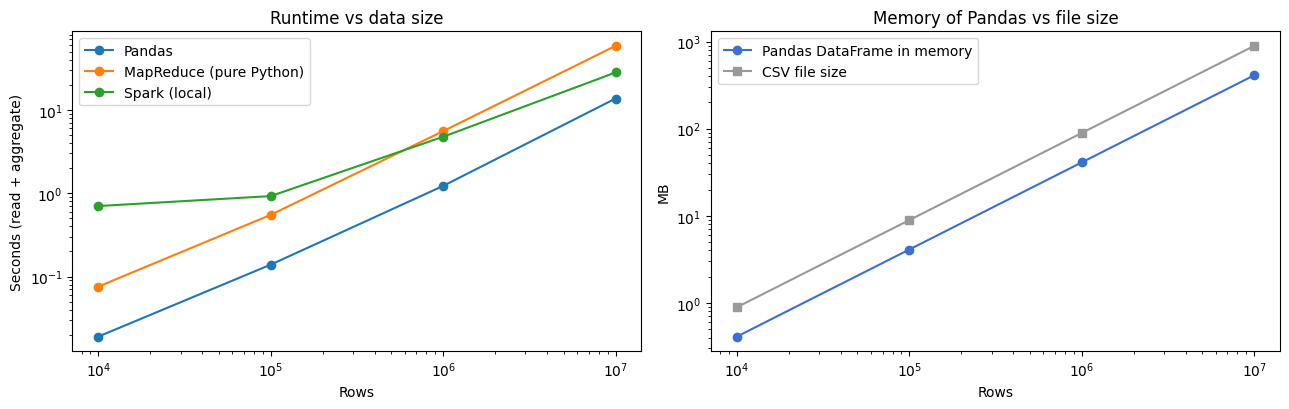

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for col, label in [("pandas_s", "Pandas"), ("mapreduce_s", "MapReduce (pure Python)"), ("spark_s", "Spark (local)")]:
    ax[0].plot(bench["rows"], bench[col], marker="o", label=label)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Rows"); ax[0].set_ylabel("Seconds (read + aggregate)"); ax[0].set_title("Runtime vs data size"); ax[0].legend()

ax[1].plot(bench["rows"], bench["pandas_memory_MB"], marker="o", color="#3b6fd4", label="Pandas DataFrame in memory")
ax[1].plot(bench["rows"], bench["file_MB"], marker="s", color="#999", label="CSV file size")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("Rows"); ax[1].set_ylabel("MB")
ax[1].set_title("Memory of Pandas vs file size"); ax[1].legend()
plt.tight_layout(); plt.show()

### How to read the scaling results (write your own conclusion from YOUR numbers)
- **Small data (10K rows):** Pandas is normally the fastest, because Spark has start-up and planning overhead. Using Spark here is not smart.
- **MapReduce (pure Python)** processes one row at a time, so its time grows roughly in a straight line with the rows. It is usually slower than Pandas, and on a machine with few cores it can even be close to Spark. The real Hadoop MapReduce also writes to disk between steps and is built for many machines, not one laptop.
- **Large data (1M to 10M rows):** check whether Spark's time grows slower than Pandas. On a machine with few cores the gap can be small.
- **Memory:** Pandas must hold the table in RAM (compare the memory column with your computer's RAM; I load only the 6 columns I need, which already saves memory). Spark and MapReduce read the data in parts.
- **Conclusion to write:** There is no fixed row count where Pandas fails (same point as Project 1). Move to Spark when the data does not fit in memory, when the job is repeated many times, or when the data already lives on many machines.

## Step 6 — Marketing Budget Recommendation Engine
**Goal:** split the next **Rs. 1,000,000** over the five platforms using the simulated historical performance.

**Method (simple and explainable):**
1. Calculate each platform's ROAS from totals.
2. Give each platform a share in proportion to `ROAS ^ alpha`. A bigger `alpha` rewards the best platform more.
3. Apply **guardrails**: no platform gets less than 5% (keep testing everywhere) or more than 45% (do not put everything in one place).
4. Estimate the expected revenue.

**Honest warning:** Expected revenue = budget × historical ROAS assumes ROAS stays the same when spend grows. In real life ROAS usually **falls** when you spend more on one platform (diminishing returns), so treat the estimate as an upper bound.

In [11]:
def recommend_budget(summary, total_budget=1_000_000, alpha=1.0, min_share=0.05, max_share=0.45):
    """Share proportional to ROAS**alpha, then forced between min_share and max_share."""
    score = summary["ROAS"] ** alpha
    fixed = {}
    while True:
        free = [p for p in score.index if p not in fixed]
        if not free:
            break
        remaining = 1 - sum(fixed.values())
        tentative = score[free] / score[free].sum() * remaining
        over, under = tentative[tentative > max_share + 1e-12], tentative[tentative < min_share - 1e-12]
        if over.empty and under.empty:
            break
        for p in over.index:  fixed[p] = max_share
        for p in under.index: fixed[p] = min_share
    share = pd.Series({p: fixed.get(p, np.nan) for p in score.index})
    free = share.isna()
    if free.any():
        share[free] = score[free] / score[free].sum() * (1 - share[~free].sum())
    out = pd.DataFrame({"historical_ROAS": summary["ROAS"], "current_spend_share": summary["spend"] / summary["spend"].sum(),
                        "recommended_share": share})
    out = out.sort_values("recommended_share", ascending=False)
    out["budget_Rs"] = (out["recommended_share"] * total_budget).round(-3)
    out.iloc[0, out.columns.get_loc("budget_Rs")] += total_budget - out["budget_Rs"].sum()   # rounding leftover goes to the top platform
    out["expected_revenue_Rs"] = out["budget_Rs"] * out["historical_ROAS"]
    return out.sort_values("recommended_share", ascending=False)

TOTAL_BUDGET = 1_000_000
rec = recommend_budget(platform_summary, TOTAL_BUDGET, alpha=1.0)
display(rec.style.format({"historical_ROAS": "{:.2f}", "current_spend_share": "{:.1%}", "recommended_share": "{:.1%}",
                          "budget_Rs": "Rs. {:,.0f}", "expected_revenue_Rs": "Rs. {:,.0f}"}))
print(f"Total allocated: Rs. {rec['budget_Rs'].sum():,.0f}")
print(f"Expected revenue (upper bound, constant ROAS): Rs. {rec['expected_revenue_Rs'].sum():,.0f}")
rec.to_csv("budget_recommendation.csv")

,historical_ROAS,current_spend_share,recommended_share,budget_Rs,expected_revenue_Rs
Instagram,6.02,24.3%,24.6%,"Rs. 246,000","Rs. 1,481,391"
Google,5.90,43.1%,24.1%,"Rs. 241,000","Rs. 1,422,163"
Facebook,5.16,18.2%,21.0%,"Rs. 210,000","Rs. 1,082,949"
TikTok,4.37,10.3%,17.8%,"Rs. 178,000","Rs. 778,210"
YouTube,3.08,4.1%,12.5%,"Rs. 125,000","Rs. 384,597"


Total allocated: Rs. 1,000,000
Expected revenue (upper bound, constant ROAS): Rs. 5,149,310


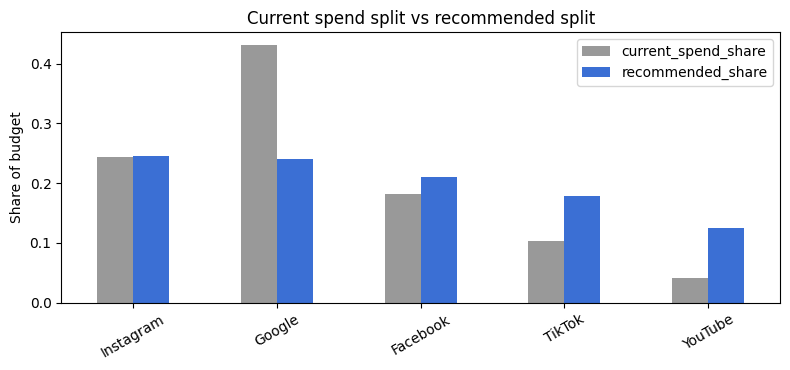

Recommended share for different alpha values:


,alpha=0.5,alpha=1,alpha=2,alpha=3
Instagram,22.3%,24.6%,28.7%,32.2%
Google,22.1%,24.1%,27.6%,30.3%
Facebook,20.6%,21.0%,21.1%,20.2%
TikTok,19.0%,17.8%,15.1%,12.3%
YouTube,15.9%,12.5%,7.5%,5.0%


In [12]:
# Chart: current spend split vs recommended split
rec[["current_spend_share", "recommended_share"]].plot(kind="bar", figsize=(8, 3.8), color=["#999", "#3b6fd4"])
plt.title("Current spend split vs recommended split"); plt.ylabel("Share of budget"); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

# Sensitivity: how much does the answer change with alpha?
sens = pd.DataFrame({f"alpha={a}": recommend_budget(platform_summary, TOTAL_BUDGET, alpha=a)["recommended_share"] for a in [0.5, 1, 2, 3]})
print("Recommended share for different alpha values:")
display(sens.style.format("{:.1%}"))

In [13]:
# Which platform + campaign combinations perform best? (only groups with enough records, to avoid lucky small groups)
combo = summarize(df, ["platform", "campaign"])
best = combo[combo["records"] >= 100].sort_values("ROAS", ascending=False).head(8)
display(best[["records", "spend", "revenue", "CPA", "ROAS"]])

records         spend        revenue     CPA  ROAS
platform  campaign                                                             
Instagram Eid Collection         408 1,046,725.630  8,472,926.440 589.041 8.095
Google    Eid Collection         332 1,724,840.110 13,067,084.130 678.804 7.576
Facebook  12.12 Sale             128   222,016.150  1,573,778.000 600.044 7.089
          11.11 Sale             105   189,523.520  1,327,088.720 603.578 7.002
          Eid Collection         443   762,999.990  5,102,036.080 641.716 6.687
Google    Winter Collection      500 2,450,233.580 14,873,831.900 864.890 6.070
Instagram Winter Collection      610 1,360,059.620  8,127,721.320 800.035 5.976
          Summer Lawn Sale       849 1,754,807.890 10,441,845.760 803.483 5.950

### Final recommendation (write in your own words)
*"In this simulated dataset, platform X has the highest ROAS (value), so the model gives it the largest share (Rs. ...). The brand should test this split for one month and compare the real ROAS using one fixed metric. Because the data is simulated and ROAS usually falls as spend rises, the result is a starting hypothesis, not a promise."*

## Step 7 — Limitations
- The data is **simulated** from my own assumptions, so platform rankings come from the numbers I chose, not from the real market.
- The simulation has no real-world effects such as diminishing returns, ad fatigue or competitor behaviour.
- ROAS shows revenue per rupee but not profit (product cost is not included).
- The recommendation assumes ROAS stays constant when budget changes.
- The scaling test uses one task (group and sum), on one machine. Results change with the task, the hardware and the file format (Parquet is much faster than CSV for Spark).
- A link between two things does not prove that one causes the other.

## Step 8 — Conclusion and next step
1. The workflow took a business question, turned it into the metrics CTR, CPC, CPA, CVR and ROAS, and ended with a budget split.
2. The scaling test showed that the right tool depends on data size and the machine: Pandas for small data, Spark when data or repeated jobs grow.
3. **Next (Project 3):** use the comment text and post data to find audience segments with clustering, and connect those needs (price, delivery, discount) back to which campaigns to run.